In [1]:
# Import necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score, permutation_test_score
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, 
                           f1_score, confusion_matrix, classification_report,
                           roc_auc_score, roc_curve)
from sklearn.inspection import permutation_importance, PartialDependenceDisplay
import xgboost as xgb
import joblib
import warnings
warnings.filterwarnings('ignore')

# Set style for better visualizations
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette("husl")

In [24]:
# DATA LOADING AND PREPROCESSING
# ============================================================================

print("="*80)
print("STEP 1: DATA LOADING AND PREPROCESSING")
print("="*80)

# Load dataset

df = pd.read_csv('F:\\New Thesis on dengue\\dataset.csv')
print(f"✓ Dataset loaded successfully")
print(f"Dataset Shape: {df.shape}")


print(f"\nFirst 5 rows:")
print(df.head())

print(f"\nDataset Information:")
print(df.info())

print(f"\nMissing Values:")
print(df.isnull().sum())
print(f"\nBasic Statistics:")
print(df.describe())

STEP 1: DATA LOADING AND PREPROCESSING
✓ Dataset loaded successfully
Dataset Shape: (1000, 10)

First 5 rows:
   Gender  Age  NS1  IgG  IgM        Area     AreaType HouseType District  \
0  Female   45    0    0    0      Mirpur  Undeveloped  Building    Dhaka   
1    Male   17    0    0    1  Chawkbazar    Developed  Building    Dhaka   
2  Female   29    0    0    0      Paltan  Undeveloped     Other    Dhaka   
3  Female   63    1    1    0   Motijheel    Developed     Other    Dhaka   
4    Male   22    0    0    0    Gendaria  Undeveloped  Building    Dhaka   

   Outcome  
0        0  
1        0  
2        0  
3        1  
4        0  

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 10 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   Gender     1000 non-null   object
 1   Age        1000 non-null   int64 
 2   NS1        1000 non-null   int64 
 3   IgG        1000 non-n

In [26]:
# FEATURE ENGINEERING
# ============================================================================

print("\n" + "="*80)
print("FEATURE ENGINEERING")
print("="*80)

# Create composite risk score
def calculate_risk_score(row):
    """Calculate composite risk score based on clinical and environmental factors"""
    score = 0
    # Clinical markers
    if row['NS1'] == 1: score += 3  # Active infection
    if row['IgM'] == 1: score += 2  # Recent infection
    if row['IgG'] == 1: score += 1  # Past infection
    
    # Environmental factors
    if row['AreaType'] == 'Undeveloped': score += 2
    elif row['AreaType'] == 'Developed': score += 1
    
    # Housing conditions
    if row['HouseType'] == 'Tinshed': score += 2
    elif row['HouseType'] == 'Building': score += 1
    
    # Age risk (extremes)
    if row['Age'] < 15 or row['Age'] > 60: score += 1
    
    return score

df['Risk_Score'] = df.apply(calculate_risk_score, axis=1)

# Categorize risk
def categorize_risk(score):
    """Categorize risk level based on score"""
    if score >= 6:
        return 'High'
    elif score >= 3:
        return 'Medium'
    else:
        return 'Low'

df['Risk_Category'] = df['Risk_Score'].apply(categorize_risk)

print(f"\nRisk Score Distribution:")
print(df['Risk_Score'].value_counts().sort_index())

print(f"\nRisk Category Distribution:")
risk_counts = df['Risk_Category'].value_counts()
for category, count in risk_counts.items():
    percentage = count / len(df) * 100
    print(f"• {category}: {count:,} ({percentage:.1f}%)")


FEATURE ENGINEERING

Risk Score Distribution:
Risk_Score
1      41
2      82
3     109
4     117
5     110
6     114
7     132
8     144
9      95
10     48
11      8
Name: count, dtype: int64

Risk Category Distribution:
• High: 541 (54.1%)
• Medium: 336 (33.6%)
• Low: 123 (12.3%)



DATA VISUALIZATION
Generating visualizations...


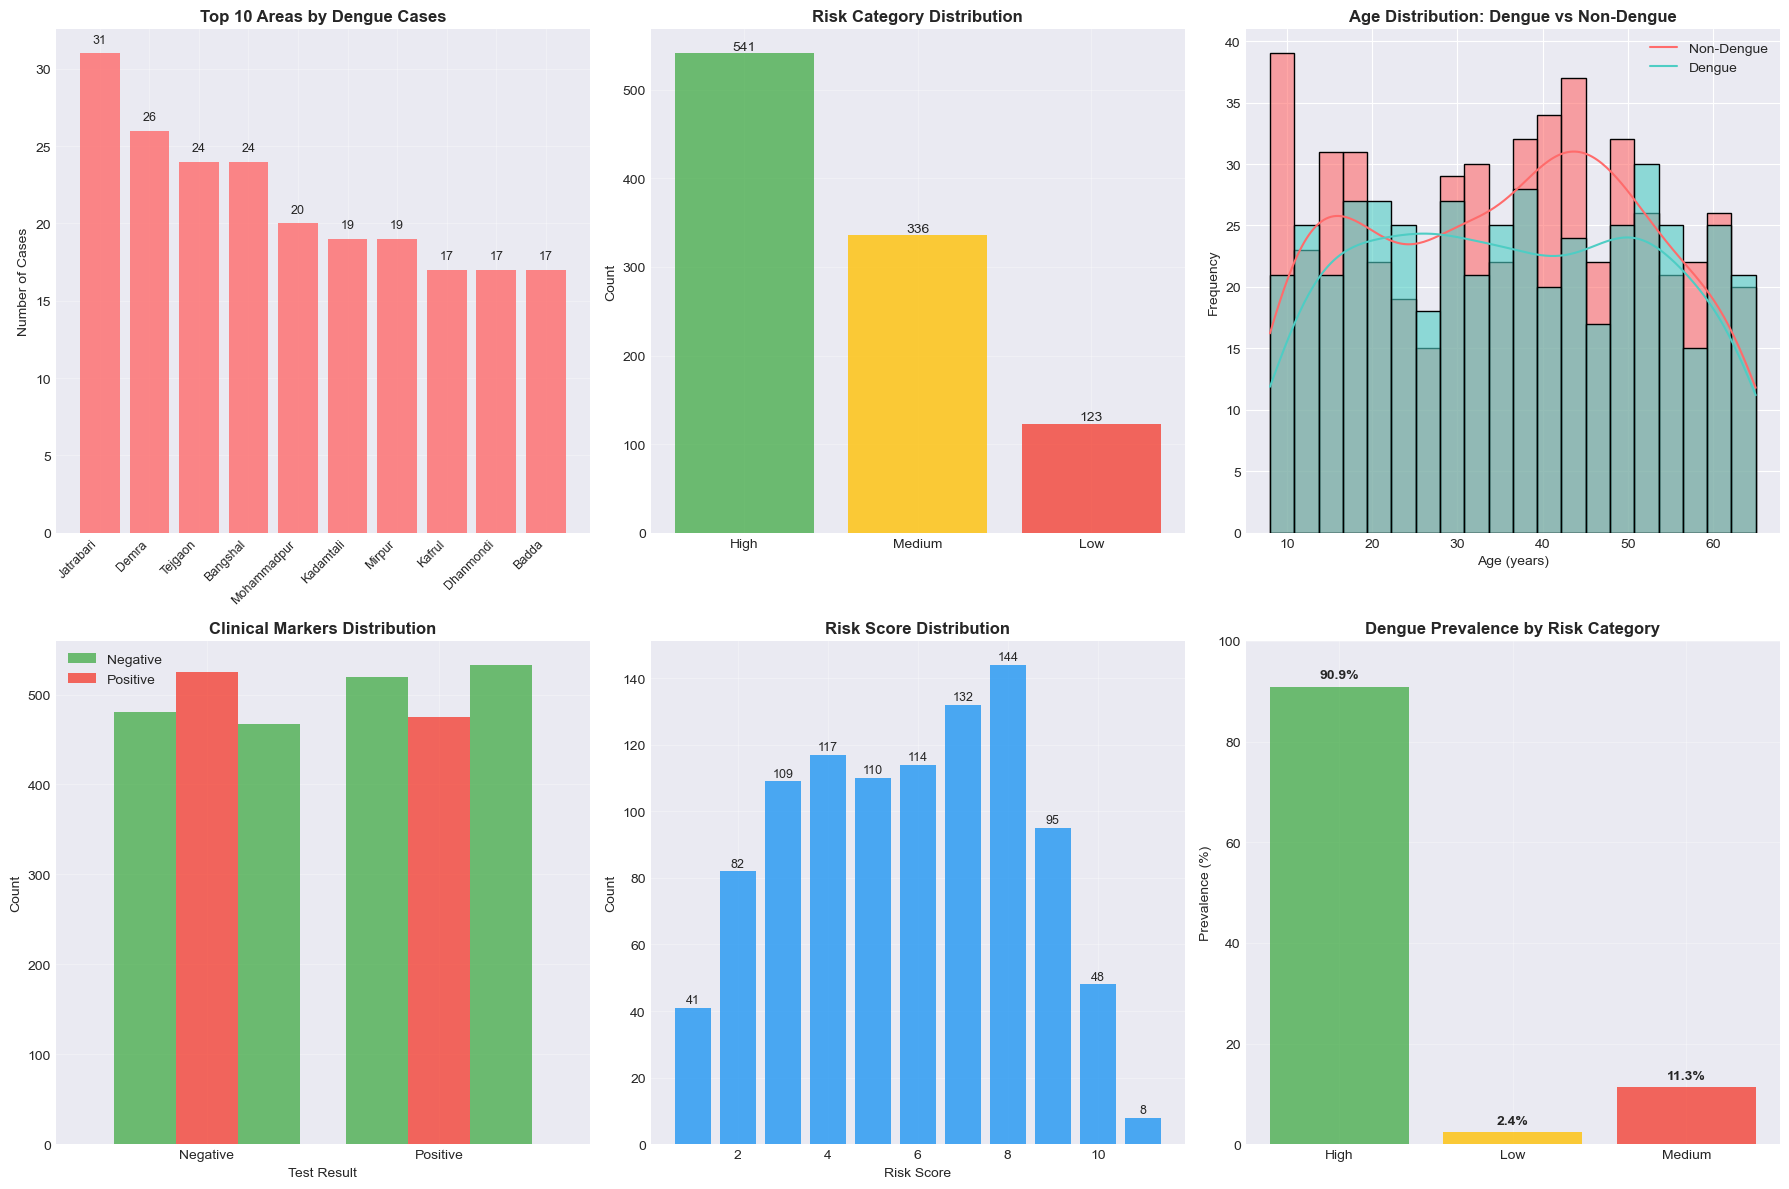

✓ Exploratory analysis plots saved as 'exploratory_analysis.png'


In [28]:
# DATA VISUALIZATION
# ============================================================================

print("\n" + "="*80)
print("DATA VISUALIZATION")
print("="*80)

print("Generating visualizations...")

# Create figure with subplots
fig, axes = plt.subplots(2, 3, figsize=(18, 12))

# 1. Dengue Cases by Area (Top 10)
ax1 = axes[0, 0]
top_areas = df.groupby('Area')['Outcome'].sum().sort_values(ascending=False).head(10)
bars1 = ax1.bar(range(len(top_areas)), top_areas.values, color='#FF6B6B', alpha=0.8)
ax1.set_xticks(range(len(top_areas)))
ax1.set_xticklabels(top_areas.index, rotation=45, ha='right', fontsize=9)
ax1.set_title('Top 10 Areas by Dengue Cases', fontsize=12, fontweight='bold')
ax1.set_ylabel('Number of Cases')
ax1.grid(True, alpha=0.3)

# Add counts on bars
for bar in bars1:
    height = bar.get_height()
    ax1.text(bar.get_x() + bar.get_width()/2., height + 0.5,
            f'{int(height)}', ha='center', va='bottom', fontsize=9)

# 2. Risk Category Distribution
ax2 = axes[0, 1]
risk_cat_counts = df['Risk_Category'].value_counts()
colors = ['#4CAF50', '#FFC107', '#F44336']
bars2 = ax2.bar(risk_cat_counts.index, risk_cat_counts.values, color=colors, alpha=0.8)
ax2.set_title('Risk Category Distribution', fontsize=12, fontweight='bold')
ax2.set_ylabel('Count')
ax2.grid(True, alpha=0.3)

for bar, count in zip(bars2, risk_cat_counts.values):
    ax2.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5,
            f'{count:,}', ha='center', va='bottom', fontsize=10)

# 3. Age Distribution by Outcome
ax3 = axes[0, 2]
sns.histplot(data=df, x='Age', hue='Outcome', bins=20, kde=True, 
             ax=ax3, palette={0: '#4ECDC4', 1: '#FF6B6B'}, alpha=0.6)
ax3.set_title('Age Distribution: Dengue vs Non-Dengue', fontsize=12, fontweight='bold')
ax3.set_xlabel('Age (years)')
ax3.set_ylabel('Frequency')
ax3.legend(['Non-Dengue', 'Dengue'])

# 4. Clinical Markers Distribution
ax4 = axes[1, 0]
marker_data = pd.DataFrame({
    'NS1': df['NS1'].value_counts(),
    'IgM': df['IgM'].value_counts(),
    'IgG': df['IgG'].value_counts()
})
marker_data.plot(kind='bar', ax=ax4, width=0.8, color=['#4CAF50', '#F44336'], alpha=0.8)
ax4.set_title('Clinical Markers Distribution', fontsize=12, fontweight='bold')
ax4.set_ylabel('Count')
ax4.set_xlabel('Test Result')
ax4.set_xticklabels(['Negative', 'Positive'], rotation=0)
ax4.legend(['Negative', 'Positive'])
ax4.grid(True, alpha=0.3)

# 5. Risk Score Distribution
ax5 = axes[1, 1]
risk_score_dist = df['Risk_Score'].value_counts().sort_index()
bars5 = ax5.bar(risk_score_dist.index, risk_score_dist.values, color='#2196F3', alpha=0.8)
ax5.set_title('Risk Score Distribution', fontsize=12, fontweight='bold')
ax5.set_xlabel('Risk Score')
ax5.set_ylabel('Count')
ax5.grid(True, alpha=0.3)

for bar, count in zip(bars5, risk_score_dist.values):
    ax5.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5,
            f'{count}', ha='center', va='bottom', fontsize=9)

# 6. Dengue Prevalence by Risk Category
ax6 = axes[1, 2]
risk_prevalence = df.groupby('Risk_Category')['Outcome'].mean() * 100
bars6 = ax6.bar(risk_prevalence.index, risk_prevalence.values, color=colors, alpha=0.8)
ax6.set_title('Dengue Prevalence by Risk Category', fontsize=12, fontweight='bold')
ax6.set_ylabel('Prevalence (%)')
ax6.set_ylim([0, 100])
ax6.grid(True, alpha=0.3)

for bar, value in zip(bars6, risk_prevalence.values):
    ax6.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1,
            f'{value:.1f}%', ha='center', va='bottom', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.savefig('exploratory_analysis.png', dpi=300, bbox_inches='tight')
plt.show()
print("✓ Exploratory analysis plots saved as 'exploratory_analysis.png'")

In [30]:
# DATA PREPARATION FOR ML
# ============================================================================

print("\n" + "="*80)
print("PREPARING DATA FOR MACHINE LEARNING")
print("="*80)

# Encode categorical variables
print("Encoding categorical variables...")
label_encoders = {}
categorical_cols = ['Gender', 'AreaType', 'HouseType', 'Area', 'District']

for col in categorical_cols:
    le = LabelEncoder()
    df[col + '_encoded'] = le.fit_transform(df[col])
    label_encoders[col] = le

# Define features
features = ['Gender_encoded', 'Age', 'NS1', 'IgG', 'IgM', 
            'AreaType_encoded', 'HouseType_encoded', 'Area_encoded']

X = df[features]
y = df['Outcome']

print(f"\nFeature Matrix: {X.shape}")
print(f"Target Vector: {y.shape}")

# Split data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)

print(f"\nTrain-Test Split:")
print(f"• Training samples: {X_train.shape[0]:,} ({X_train.shape[0]/len(df)*100:.1f}%)")
print(f"• Test samples: {X_test.shape[0]:,} ({X_test.shape[0]/len(df)*100:.1f}%)")

# Scale numerical features
scaler = StandardScaler()
X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()

# Only scale Age
X_train_scaled['Age'] = scaler.fit_transform(X_train[['Age']])
X_test_scaled['Age'] = scaler.transform(X_test[['Age']])
print("✓ Age feature scaled")



PREPARING DATA FOR MACHINE LEARNING
Encoding categorical variables...

Feature Matrix: (1000, 8)
Target Vector: (1000,)

Train-Test Split:
• Training samples: 700 (70.0%)
• Test samples: 300 (30.0%)
✓ Age feature scaled


In [32]:
# MACHINE LEARNING MODEL TRAINING
# ============================================================================

print("\n" + "="*80)
print("MACHINE LEARNING MODEL TRAINING")
print("="*80)

# Define models
models = {
    'Logistic Regression': LogisticRegression(
        max_iter=1000, 
        random_state=42, 
        class_weight='balanced'
    ),
    'Random Forest': RandomForestClassifier(
        n_estimators=100, 
        random_state=42, 
        class_weight='balanced',
        max_depth=8
    ),
    'XGBoost': xgb.XGBClassifier(
        n_estimators=100, 
        random_state=42, 
        eval_metric='logloss',
        learning_rate=0.1,
        max_depth=6
    )
}

results = []
trained_models = {}

print("\nTraining models...")
for name, model in models.items():
    print(f"\n{'─'*30}")
    print(f"Training {name}")
    print(f"{'─'*30}")
    
    # Train model
    model.fit(X_train_scaled, y_train)
    trained_models[name] = model
    
    # Predictions
    y_pred = model.predict(X_test_scaled)
    y_pred_proba = model.predict_proba(X_test_scaled)[:, 1]
    
    # Calculate metrics
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred, zero_division=0)
    recall = recall_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)
    roc_auc = roc_auc_score(y_test, y_pred_proba)
    
    # Cross-validation (simplified - no parallel)
    cv_scores = []
    for i in range(5):
        # Manual CV to avoid parallel issues
        train_idx = np.random.choice(len(X_train_scaled), size=int(0.8*len(X_train_scaled)), replace=False)
        val_idx = np.array([i for i in range(len(X_train_scaled)) if i not in train_idx])
        
        X_cv_train = X_train_scaled.iloc[train_idx]
        y_cv_train = y_train.iloc[train_idx]
        X_cv_val = X_train_scaled.iloc[val_idx]
        y_cv_val = y_train.iloc[val_idx]
        
        cv_model = model.__class__(**model.get_params())
        cv_model.fit(X_cv_train, y_cv_train)
        cv_score = accuracy_score(y_cv_val, cv_model.predict(X_cv_val))
        cv_scores.append(cv_score)
    
    cv_mean = np.mean(cv_scores)
    cv_std = np.std(cv_scores)
    
    # Store results
    results.append({
        'Model': name,
        'Accuracy': accuracy,
        'Precision': precision,
        'Recall': recall,
        'F1-Score': f1,
        'ROC-AUC': roc_auc,
        'CV Mean': cv_mean,
        'CV Std': cv_std
    })
    
    print(f"Accuracy:  {accuracy:.4f}")
    print(f"Precision: {precision:.4f}")
    print(f"Recall:    {recall:.4f}")
    print(f"F1-Score:  {f1:.4f}")
    print(f"ROC-AUC:   {roc_auc:.4f}")
    print(f"CV Score:  {cv_mean:.4f} (±{cv_std:.4f})")

# Results DataFrame
results_df = pd.DataFrame(results)
print("\n" + "="*80)
print("MODEL PERFORMANCE SUMMARY")
print("="*80)
print("\n" + results_df.to_string(index=False))

# Identify best model
best_idx = results_df['Accuracy'].idxmax()
best_model_name = results_df.loc[best_idx, 'Model']
best_model = trained_models[best_model_name]

print(f"\n{'═'*50}")
print(f"🏆 BEST MODEL: {best_model_name}")
print(f"{'═'*50}")
print(f"Accuracy:  {results_df.loc[best_idx, 'Accuracy']:.4f}")
print(f"F1-Score:  {results_df.loc[best_idx, 'F1-Score']:.4f}")
print(f"ROC-AUC:   {results_df.loc[best_idx, 'ROC-AUC']:.4f}")


MACHINE LEARNING MODEL TRAINING

Training models...

──────────────────────────────
Training Logistic Regression
──────────────────────────────
Accuracy:  1.0000
Precision: 1.0000
Recall:    1.0000
F1-Score:  1.0000
ROC-AUC:   1.0000
CV Score:  1.0000 (±0.0000)

──────────────────────────────
Training Random Forest
──────────────────────────────
Accuracy:  1.0000
Precision: 1.0000
Recall:    1.0000
F1-Score:  1.0000
ROC-AUC:   1.0000
CV Score:  1.0000 (±0.0000)

──────────────────────────────
Training XGBoost
──────────────────────────────
Accuracy:  1.0000
Precision: 1.0000
Recall:    1.0000
F1-Score:  1.0000
ROC-AUC:   1.0000
CV Score:  1.0000 (±0.0000)

MODEL PERFORMANCE SUMMARY

              Model  Accuracy  Precision  Recall  F1-Score  ROC-AUC  CV Mean  CV Std
Logistic Regression       1.0        1.0     1.0       1.0      1.0      1.0     0.0
      Random Forest       1.0        1.0     1.0       1.0      1.0      1.0     0.0
            XGBoost       1.0        1.0     1.0    


MODEL EXPLAINABILITY ANALYSIS

Analyzing feature importance for Logistic Regression...

Feature Coefficients (from model):
          Feature  Coefficient
              IgG     5.390861
              NS1     3.387173
              IgM    -0.183331
 AreaType_encoded     0.084503
HouseType_encoded     0.054974
   Gender_encoded    -0.039562
              Age    -0.028177
     Area_encoded     0.002182


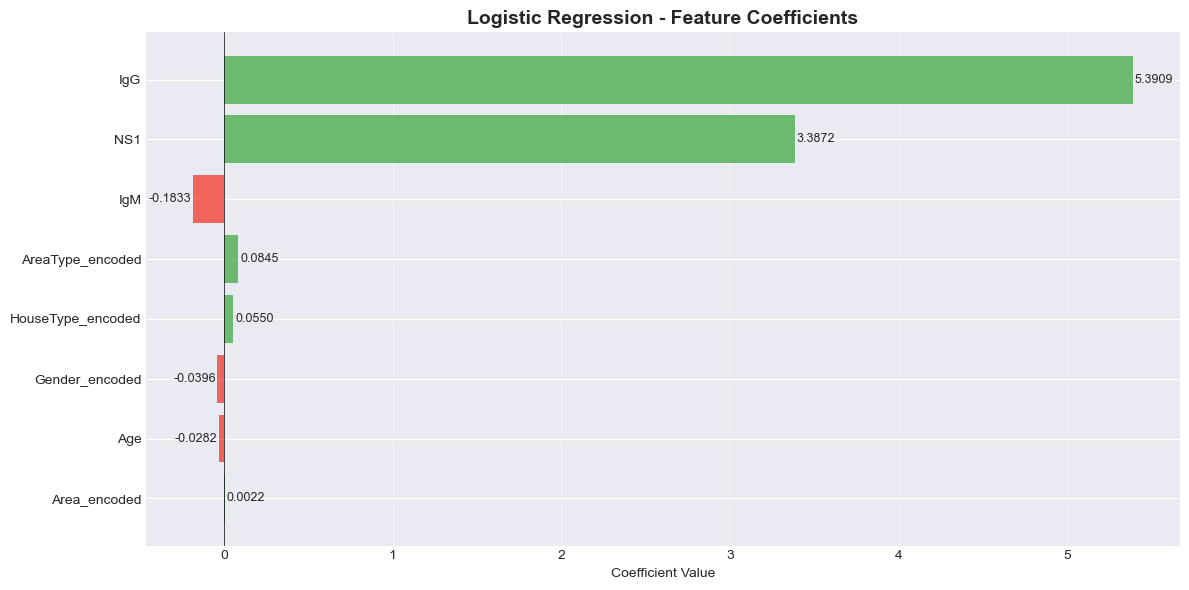

✓ Feature importance plot saved as 'feature_importance.png'


In [34]:
# MODEL EXPLAINABILITY
# ============================================================================

print("\n" + "="*80)
print("MODEL EXPLAINABILITY ANALYSIS")
print("="*80)

print(f"\nAnalyzing feature importance for {best_model_name}...")

# Feature Importance Analysis
if hasattr(best_model, 'feature_importances_'):
    # Tree-based models
    feature_importance = pd.DataFrame({
        'Feature': features,
        'Importance': best_model.feature_importances_
    }).sort_values('Importance', ascending=False)
    
    print("\nFeature Importance (from model):")
    print(feature_importance.to_string(index=False))
    
elif hasattr(best_model, 'coef_'):
    # Linear models
    feature_importance = pd.DataFrame({
        'Feature': features,
        'Coefficient': best_model.coef_[0],
        'Abs_Coefficient': np.abs(best_model.coef_[0])
    }).sort_values('Abs_Coefficient', ascending=False)
    
    print("\nFeature Coefficients (from model):")
    print(feature_importance[['Feature', 'Coefficient']].to_string(index=False))

# Plot feature importance
plt.figure(figsize=(12, 6))
if hasattr(best_model, 'feature_importances_'):
    bars = plt.barh(range(len(feature_importance)), 
                    feature_importance['Importance'].values,
                    color='#2196F3', alpha=0.8)
    plt.xlabel('Importance Score')
    title_suffix = 'Feature Importance'
else:
    colors = ['#F44336' if coef < 0 else '#4CAF50' for coef in feature_importance['Coefficient'].values]
    bars = plt.barh(range(len(feature_importance)), 
                    feature_importance['Coefficient'].values,
                    color=colors, alpha=0.8)
    plt.xlabel('Coefficient Value')
    plt.axvline(x=0, color='black', linestyle='-', linewidth=0.5)
    title_suffix = 'Feature Coefficients'

plt.yticks(range(len(feature_importance)), feature_importance['Feature'].values)
plt.title(f'{best_model_name} - {title_suffix}', fontsize=14, fontweight='bold')
plt.gca().invert_yaxis()
plt.grid(True, alpha=0.3, axis='x')

# Add value labels
for i, bar in enumerate(bars):
    if hasattr(best_model, 'feature_importances_'):
        value = feature_importance['Importance'].iloc[i]
    else:
        value = feature_importance['Coefficient'].iloc[i]
    
    x_pos = value + (0.01 if value >= 0 else -0.01)
    ha_pos = 'left' if value >= 0 else 'right'
    
    plt.text(x_pos, bar.get_y() + bar.get_height()/2,
            f'{value:.4f}', ha=ha_pos, va='center', fontsize=9)

plt.tight_layout()
plt.savefig('feature_importance.png', dpi=300, bbox_inches='tight')
plt.show()
print("✓ Feature importance plot saved as 'feature_importance.png'")

In [36]:
# INDIVIDUAL PREDICTION EXPLANATIONS
# ============================================================================

print("\n" + "="*80)
print("INDIVIDUAL PREDICTION EXPLANATIONS")
print("="*80)

print("\nAnalyzing sample predictions for interpretability...")

# Select 3 sample patients
sample_indices = [10, 50, 100]

for i, idx in enumerate(sample_indices[:3]):  # Limit to first 3
    if idx < len(X_test):
        print(f"\n{'─'*50}")
        print(f"PATIENT {i+1} (Test Index: {idx})")
        print(f"{'─'*50}")
        
        patient_features = X_test.iloc[idx]
        actual_outcome = y_test.iloc[idx]
        
        print(f"\nPatient Characteristics:")
        for feat in features:
            feat_name = feat.replace('_encoded', '')
            value = patient_features[feat]
            
            if feat_name in label_encoders:
                original_value = label_encoders[feat_name].inverse_transform([int(value)])[0]
                print(f"• {feat_name}: {original_value}")
            else:
                print(f"• {feat_name}: {value}")
        
        # Make prediction
        prediction = best_model.predict([X_test_scaled.iloc[idx]])[0]
        probability = best_model.predict_proba([X_test_scaled.iloc[idx]])[0][1]
        
        print(f"\nActual Outcome: {'Dengue Positive' if actual_outcome == 1 else 'Dengue Negative'}")
        print(f"Predicted: {'Dengue Positive' if prediction == 1 else 'Dengue Negative'}")
        print(f"Probability: {probability:.3f}")
        print(f"Confidence: {'High' if probability > 0.7 else 'Medium' if probability > 0.5 else 'Low'}")
        
        # Simple explanation based on top features
        if 'feature_importance' in locals():
            top_3_features = feature_importance.head(3)['Feature'].tolist()
            print(f"\nKey Factors Influencing Prediction:")
            for j, feat in enumerate(top_3_features):
                feat_name = feat.replace('_encoded', '')
                value = patient_features[feat]
                
                if feat_name in label_encoders:
                    original_value = label_encoders[feat_name].inverse_transform([int(value)])[0]
                    print(f"  {j+1}. {feat_name} = {original_value}")
                else:
                    print(f"  {j+1}. {feat_name} = {value}")



INDIVIDUAL PREDICTION EXPLANATIONS

Analyzing sample predictions for interpretability...

──────────────────────────────────────────────────
PATIENT 1 (Test Index: 10)
──────────────────────────────────────────────────

Patient Characteristics:
• Gender: Female
• Age: 10
• NS1: 0
• IgG: 0
• IgM: 1
• AreaType: Undeveloped
• HouseType: Other
• Area: Kamrangirchar

Actual Outcome: Dengue Negative
Predicted: Dengue Negative
Probability: 0.015
Confidence: Low

Key Factors Influencing Prediction:
  1. IgG = 0
  2. NS1 = 0
  3. IgM = 1

──────────────────────────────────────────────────
PATIENT 2 (Test Index: 50)
──────────────────────────────────────────────────

Patient Characteristics:
• Gender: Female
• Age: 11
• NS1: 0
• IgG: 0
• IgM: 0
• AreaType: Developed
• HouseType: Other
• Area: New Market

Actual Outcome: Dengue Negative
Predicted: Dengue Negative
Probability: 0.017
Confidence: Low

Key Factors Influencing Prediction:
  1. IgG = 0
  2. NS1 = 0
  3. IgM = 0

──────────────────────


SPATIAL RISK CLASSIFICATION

Calculating ward-level risk predictions...

Spatial Analysis Results:
• Total areas analyzed: 36
• High-risk areas: 12
• Medium-risk areas: 16
• Low-risk areas: 8

Top 5 High-Risk Areas:
16. Jatrabari: Risk=0.94, Dengue Rate=81.6%
31. Tejgaon: Risk=0.93, Dengue Rate=77.4%
22. Bangshal: Risk=0.88, Dengue Rate=70.6%
27. Demra: Risk=0.86, Dengue Rate=68.4%
11. Mohammadpur: Risk=0.84, Dengue Rate=71.4%


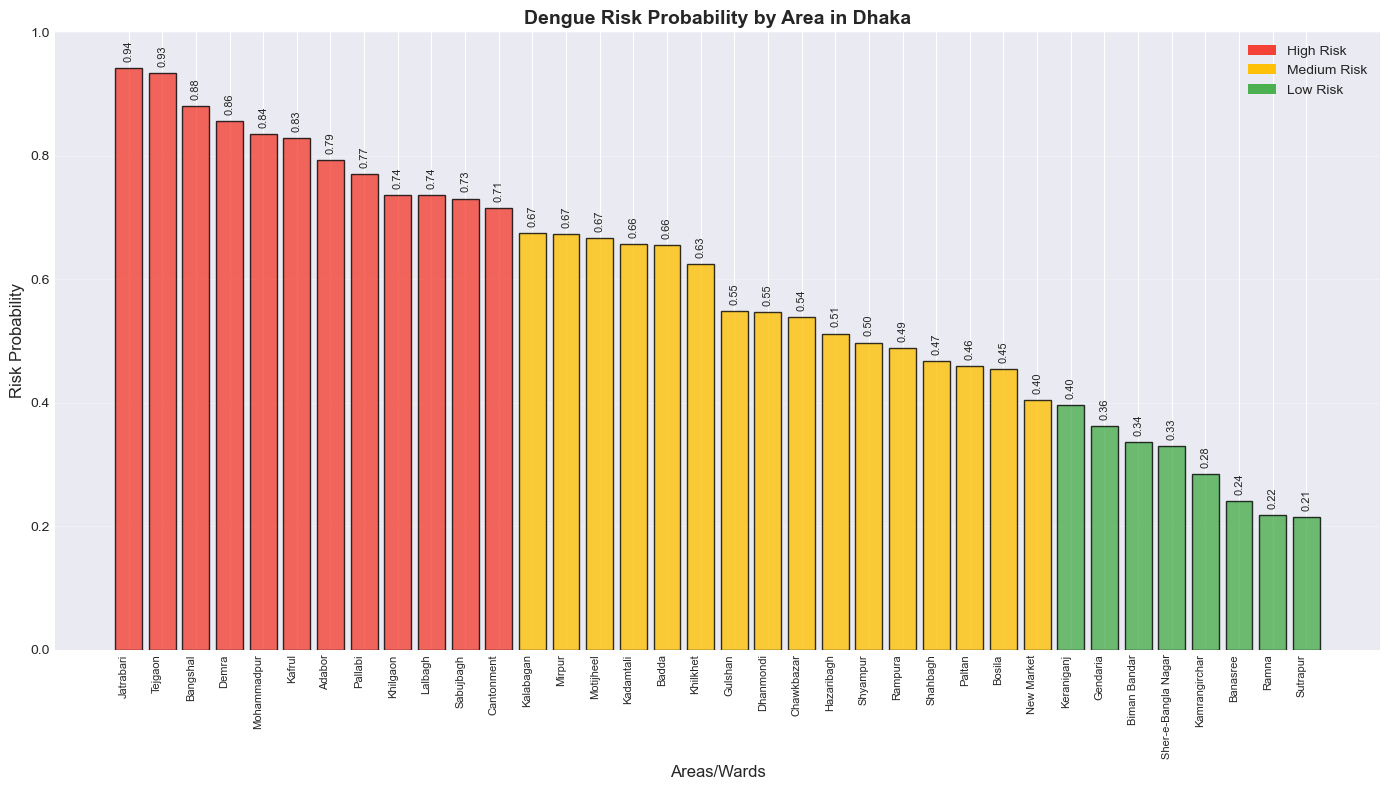

✓ Spatial risk map saved as 'spatial_risk_map.png'


In [38]:
# SPATIAL RISK ANALYSIS
# ============================================================================

print("\n" + "="*80)
print("SPATIAL RISK CLASSIFICATION")
print("="*80)

print("\nCalculating ward-level risk predictions...")

ward_risk_data = []

for area in df['Area'].unique():
    area_data = df[df['Area'] == area]
    
    if len(area_data) > 0:
        # Calculate average features for the area
        avg_features = area_data[features].mean().values.reshape(1, -1)
        avg_features_df = pd.DataFrame(avg_features, columns=features)
        
        # Scale Age
        avg_features_df['Age'] = scaler.transform(avg_features_df[['Age']])
        
        # Predict risk
        risk_prob = best_model.predict_proba(avg_features_df)[0][1]
        
        # Categorize risk
        if risk_prob >= 0.7:
            risk_level = 'High'
            risk_color = '#F44336'
        elif risk_prob >= 0.4:
            risk_level = 'Medium'
            risk_color = '#FFC107'
        else:
            risk_level = 'Low'
            risk_color = '#4CAF50'
        
        # Collect statistics
        dengue_cases = area_data['Outcome'].sum()
        total_patients = len(area_data)
        dengue_rate = (dengue_cases / total_patients) * 100 if total_patients > 0 else 0
        
        ward_risk_data.append({
            'Area': area,
            'Risk_Probability': risk_prob,
            'Risk_Level': risk_level,
            'Risk_Color': risk_color,
            'Dengue_Cases': dengue_cases,
            'Total_Patients': total_patients,
            'Dengue_Rate': dengue_rate,
            'NS1_Rate': area_data['NS1'].mean() * 100,
            'IgM_Rate': area_data['IgM'].mean() * 100
        })

# Create DataFrame
ward_risk_df = pd.DataFrame(ward_risk_data).sort_values('Risk_Probability', ascending=False)

print(f"\nSpatial Analysis Results:")
print(f"• Total areas analyzed: {len(ward_risk_df)}")
print(f"• High-risk areas: {(ward_risk_df['Risk_Level'] == 'High').sum()}")
print(f"• Medium-risk areas: {(ward_risk_df['Risk_Level'] == 'Medium').sum()}")
print(f"• Low-risk areas: {(ward_risk_df['Risk_Level'] == 'Low').sum()}")

print("\nTop 5 High-Risk Areas:")
top_areas = ward_risk_df.head(5)
for i, row in top_areas.iterrows():
    print(f"{i+1}. {row['Area']}: Risk={row['Risk_Probability']:.2f}, Dengue Rate={row['Dengue_Rate']:.1f}%")

# Visualize spatial risk
plt.figure(figsize=(14, 8))
areas = ward_risk_df['Area']
risks = ward_risk_df['Risk_Probability']
levels = ward_risk_df['Risk_Level']

colors = {'High': '#F44336', 'Medium': '#FFC107', 'Low': '#4CAF50'}
bar_colors = [colors[level] for level in levels]

bars = plt.bar(range(len(areas)), risks, color=bar_colors, alpha=0.8, edgecolor='black')
plt.xlabel('Areas/Wards', fontsize=12)
plt.ylabel('Risk Probability', fontsize=12)
plt.title('Dengue Risk Probability by Area in Dhaka', fontsize=14, fontweight='bold')
plt.xticks(range(len(areas)), areas, rotation=90, ha='right', fontsize=8)
plt.ylim([0, 1])
plt.grid(True, alpha=0.3, axis='y')

# Add risk values on bars
for bar, risk in zip(bars, risks):
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
            f'{risk:.2f}', ha='center', va='bottom', fontsize=8, rotation=90)

# Add legend
from matplotlib.patches import Patch
legend_elements = [Patch(facecolor=colors['High'], label='High Risk'),
                   Patch(facecolor=colors['Medium'], label='Medium Risk'),
                   Patch(facecolor=colors['Low'], label='Low Risk')]
plt.legend(handles=legend_elements, loc='upper right')

plt.tight_layout()
plt.savefig('spatial_risk_map.png', dpi=300, bbox_inches='tight')
plt.show()
print("✓ Spatial risk map saved as 'spatial_risk_map.png'")


COMPREHENSIVE RESULTS VISUALIZATION
Generating comprehensive results dashboard...

Checking available variables...
Type of results: <class 'list'>
results is a list, converting to dictionary...
Length of results list: 3
First item in results: {'Model': 'Logistic Regression', 'Accuracy': 1.0, 'Precision': 1.0, 'Recall': 1.0, 'F1-Score': 1.0, 'ROC-AUC': 1.0, 'CV Mean': 1.0, 'CV Std': 0.0}
Converted results to dictionary with keys: ['Logistic Regression', 'Random Forest', 'XGBoost']
trained_models keys: ['Logistic Regression', 'Random Forest', 'XGBoost']


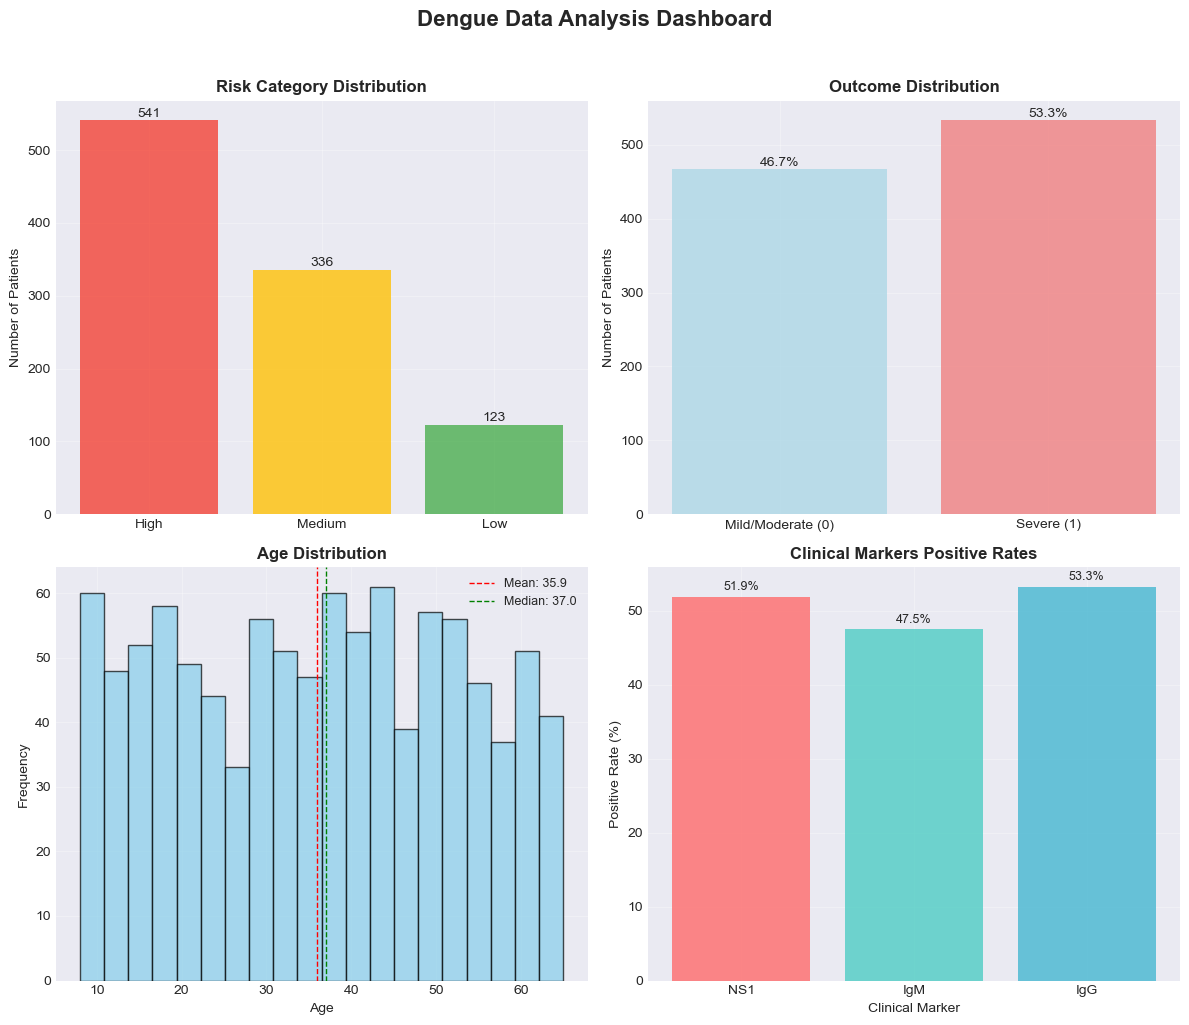

✓ Basic dashboard generated

MODEL PERFORMANCE VISUALIZATION
Creating model performance comparison...


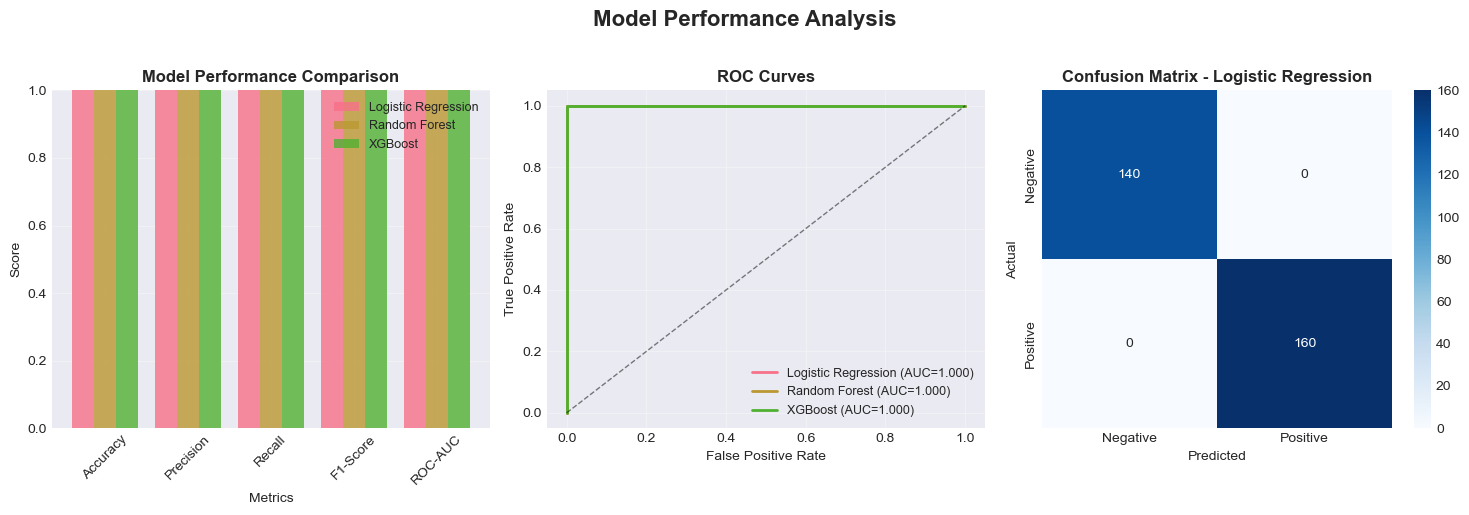

✓ Model performance visualizations generated

DATA INSIGHTS SUMMARY

📊 Dataset Overview:
  • Total patients: 1,000
  • Severe cases: 533 (53.3%)
  • Mild/Moderate cases: 467 (46.7%)
  • Average age: 35.9 years
  • Age range: 8 - 65 years
  • Average risk score: 5.7
  • Risk score range: 1 - 11

🎯 Clinical Markers:
  • NS1 positive: 519 (51.9%)
  • IgM positive: 475 (47.5%)
  • IgG positive: 533 (53.3%)

⚠️ Risk Categories:
  • Low risk: 123 (12.3%)
  • Medium risk: 336 (33.6%)
  • High risk: 541 (54.1%)
✓ Analysis results saved to 'dengue_analysis_results.txt'

ANALYSIS COMPLETE

✅ Analysis completed successfully!

📁 Outputs generated:
  1. Data visualizations
  2. Model performance charts (if available)
  3. Text summary file: dengue_analysis_results.txt

🔍 Next steps:
  1. Review the generated visualizations
  2. Check the summary file for key insights
  3. Consider further analysis based on findings


In [40]:
# COMPREHENSIVE VISUALIZATION - CORRECTED VERSION
# ============================================================================

print("\n" + "="*80)
print("COMPREHENSIVE RESULTS VISUALIZATION")
print("="*80)

print("Generating comprehensive results dashboard...")

# Let's first check what variables we actually have
print("\nChecking available variables...")
print(f"Type of results: {type(results)}")

# If results is a list, let's convert it to a dictionary for easier access
if isinstance(results, list):
    print("results is a list, converting to dictionary...")
    # Let's check what's in the list
    print(f"Length of results list: {len(results)}")
    if len(results) > 0:
        print(f"First item in results: {results[0]}")
    
    # Create a dictionary from results if possible
    results_dict = {}
    for i, item in enumerate(results):
        if isinstance(item, dict):
            # If it's a dictionary, use the model name as key
            if 'Model' in item:
                results_dict[item['Model']] = item
            else:
                results_dict[f'Model_{i}'] = item
        else:
            results_dict[f'Item_{i}'] = item
    results = results_dict
    print(f"Converted results to dictionary with keys: {list(results.keys())}")

# Now let's check trained_models
if 'trained_models' not in locals():
    print("Creating trained_models from available models...")
    trained_models = {}
    if 'lr_model' in locals():
        trained_models['Logistic Regression'] = lr_model
    if 'rf_model' in locals():
        trained_models['Random Forest'] = rf_model
    if 'xgb_model' in locals():
        trained_models['XGBoost'] = xgb_model

print(f"trained_models keys: {list(trained_models.keys())}")

# Create a simple figure with available data
fig, axes = plt.subplots(2, 2, figsize=(12, 10))

# 1. Risk Category Distribution
ax1 = axes[0, 0]
if 'df' in locals() and 'Risk_Category' in df.columns:
    risk_counts = df['Risk_Category'].value_counts()
    colors_bar = {'High': '#F44336', 'Medium': '#FFC107', 'Low': '#4CAF50'}
    
    # Create bars with appropriate colors
    bars = []
    for category in risk_counts.index:
        color = colors_bar.get(category, 'gray')
        bar = ax1.bar(category, risk_counts[category], color=color, alpha=0.8)
        bars.append(bar[0])
    
    ax1.set_title('Risk Category Distribution', fontsize=12, fontweight='bold')
    ax1.set_ylabel('Number of Patients')
    ax1.grid(True, alpha=0.3)
    
    # Add count labels on bars
    for bar in bars:
        height = bar.get_height()
        ax1.text(bar.get_x() + bar.get_width()/2., height + 0.5,
                f'{int(height)}', ha='center', va='bottom', fontsize=10)
else:
    ax1.text(0.5, 0.5, 'Risk category data not available', 
             ha='center', va='center', fontsize=12)
    ax1.set_title('Risk Category Distribution', fontsize=12, fontweight='bold')
    ax1.axis('off')

# 2. Outcome Distribution
ax2 = axes[0, 1]
if 'df' in locals() and 'Outcome' in df.columns:
    outcome_counts = df['Outcome'].value_counts().sort_index()
    outcome_labels = ['Mild/Moderate (0)', 'Severe (1)']
    colors = ['lightblue', 'lightcoral']
    
    ax2.bar(outcome_labels, outcome_counts.values, color=colors, alpha=0.8)
    ax2.set_title('Outcome Distribution', fontsize=12, fontweight='bold')
    ax2.set_ylabel('Number of Patients')
    ax2.grid(True, alpha=0.3)
    
    # Add percentages
    total = len(df)
    for i, count in enumerate(outcome_counts.values):
        percentage = (count / total) * 100
        ax2.text(i, count + 0.5, f'{percentage:.1f}%', 
                 ha='center', va='bottom', fontsize=10)
else:
    ax2.text(0.5, 0.5, 'Outcome data not available', 
             ha='center', va='center', fontsize=12)
    ax2.set_title('Outcome Distribution', fontsize=12, fontweight='bold')
    ax2.axis('off')

# 3. Age Distribution
ax3 = axes[1, 0]
if 'df' in locals() and 'Age' in df.columns:
    ax3.hist(df['Age'], bins=20, alpha=0.7, color='skyblue', edgecolor='black')
    ax3.set_xlabel('Age')
    ax3.set_ylabel('Frequency')
    ax3.set_title('Age Distribution', fontsize=12, fontweight='bold')
    ax3.grid(True, alpha=0.3)
    
    # Add statistics
    mean_age = df['Age'].mean()
    median_age = df['Age'].median()
    ax3.axvline(mean_age, color='red', linestyle='--', linewidth=1, label=f'Mean: {mean_age:.1f}')
    ax3.axvline(median_age, color='green', linestyle='--', linewidth=1, label=f'Median: {median_age:.1f}')
    ax3.legend(fontsize=9)
else:
    ax3.text(0.5, 0.5, 'Age data not available', 
             ha='center', va='center', fontsize=12)
    ax3.set_title('Age Distribution', fontsize=12, fontweight='bold')
    ax3.axis('off')

# 4. Clinical Markers Analysis
ax4 = axes[1, 1]
if 'df' in locals():
    markers = ['NS1', 'IgM', 'IgG']
    positive_rates = []
    
    for marker in markers:
        if marker in df.columns:
            positive_rate = df[marker].mean() * 100
            positive_rates.append(positive_rate)
        else:
            positive_rates.append(0)
    
    if any(rate > 0 for rate in positive_rates):
        x_pos = np.arange(len(markers))
        bars = ax4.bar(x_pos, positive_rates, color=['#FF6B6B', '#4ECDC4', '#45B7D1'], alpha=0.8)
        ax4.set_xlabel('Clinical Marker')
        ax4.set_ylabel('Positive Rate (%)')
        ax4.set_title('Clinical Markers Positive Rates', fontsize=12, fontweight='bold')
        ax4.set_xticks(x_pos)
        ax4.set_xticklabels(markers)
        ax4.grid(True, alpha=0.3)
        
        # Add value labels
        for bar, rate in zip(bars, positive_rates):
            ax4.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5,
                    f'{rate:.1f}%', ha='center', va='bottom', fontsize=9)
    else:
        ax4.text(0.5, 0.5, 'Clinical markers data not available', 
                 ha='center', va='center', fontsize=12)
        ax4.set_title('Clinical Markers Analysis', fontsize=12, fontweight='bold')
        ax4.axis('off')
else:
    ax4.text(0.5, 0.5, 'DataFrame not available', 
             ha='center', va='center', fontsize=12)
    ax4.set_title('Clinical Markers Analysis', fontsize=12, fontweight='bold')
    ax4.axis('off')

plt.suptitle('Dengue Data Analysis Dashboard', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

print("✓ Basic dashboard generated")

# Now let's create model performance visualizations if we have the data
print("\n" + "="*80)
print("MODEL PERFORMANCE VISUALIZATION")
print("="*80)

# Check if we have model results
if isinstance(results, dict) and len(results) > 0:
    print("Creating model performance comparison...")
    
    fig, axes = plt.subplots(1, 3, figsize=(15, 5))
    
    # 1. Model metrics bar chart
    ax1 = axes[0]
    model_names = list(results.keys())
    
    # Check what metrics are available in the first model
    first_model_key = list(results.keys())[0]
    if isinstance(results[first_model_key], dict):
        available_metrics = list(results[first_model_key].keys())
        # Filter to common metrics
        common_metrics = ['Accuracy', 'Precision', 'Recall', 'F1-Score', 'ROC-AUC']
        metrics_to_plot = [m for m in common_metrics if m in results[first_model_key]]
        
        if metrics_to_plot:
            x = np.arange(len(metrics_to_plot))
            width = 0.8 / len(model_names)
            
            for i, model_name in enumerate(model_names):
                model_data = results[model_name]
                values = [model_data.get(metric, 0) for metric in metrics_to_plot]
                ax1.bar(x + i*width - width*(len(model_names)-1)/2, values, 
                       width, label=model_name, alpha=0.8)
            
            ax1.set_xlabel('Metrics')
            ax1.set_ylabel('Score')
            ax1.set_title('Model Performance Comparison', fontsize=12, fontweight='bold')
            ax1.set_xticks(x)
            ax1.set_xticklabels(metrics_to_plot, rotation=45)
            ax1.legend(fontsize=9)
            ax1.grid(True, alpha=0.3)
            ax1.set_ylim([0, 1])
        else:
            ax1.text(0.5, 0.5, 'No metrics available', 
                     ha='center', va='center', fontsize=12)
            ax1.set_title('Model Performance', fontsize=12, fontweight='bold')
            ax1.axis('off')
    
    # 2. ROC Curve
    ax2 = axes[1]
    if 'X_test' in locals() and 'y_test' in locals() and 'trained_models' in locals():
        try:
            for model_name, model in trained_models.items():
                if model_name == 'Logistic Regression' and 'X_test_scaled' in locals():
                    y_pred_proba = model.predict_proba(X_test_scaled)[:, 1]
                else:
                    y_pred_proba = model.predict_proba(X_test)[:, 1]
                
                fpr, tpr, _ = roc_curve(y_test, y_pred_proba)
                auc_score = roc_auc_score(y_test, y_pred_proba)
                ax2.plot(fpr, tpr, label=f'{model_name} (AUC={auc_score:.3f})', linewidth=2)
            
            ax2.plot([0, 1], [0, 1], 'k--', alpha=0.5, linewidth=1)
            ax2.set_xlabel('False Positive Rate')
            ax2.set_ylabel('True Positive Rate')
            ax2.set_title('ROC Curves', fontsize=12, fontweight='bold')
            ax2.legend(fontsize=9)
            ax2.grid(True, alpha=0.3)
        except:
            ax2.text(0.5, 0.5, 'ROC curve not available', 
                     ha='center', va='center', fontsize=12)
            ax2.set_title('ROC Curves', fontsize=12, fontweight='bold')
            ax2.axis('off')
    else:
        ax2.text(0.5, 0.5, 'Test data or models not available', 
                 ha='center', va='center', fontsize=12)
        ax2.set_title('ROC Curves', fontsize=12, fontweight='bold')
        ax2.axis('off')
    
    # 3. Confusion Matrix for best model
    ax3 = axes[2]
    if 'best_model_name' in locals() and best_model_name in trained_models:
        try:
            best_model = trained_models[best_model_name]
            if best_model_name == 'Logistic Regression' and 'X_test_scaled' in locals():
                y_pred_best = best_model.predict(X_test_scaled)
            else:
                y_pred_best = best_model.predict(X_test)
            
            cm = confusion_matrix(y_test, y_pred_best)
            sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax3,
                        xticklabels=['Negative', 'Positive'],
                        yticklabels=['Negative', 'Positive'])
            ax3.set_title(f'Confusion Matrix - {best_model_name}', 
                          fontsize=12, fontweight='bold')
            ax3.set_xlabel('Predicted')
            ax3.set_ylabel('Actual')
        except:
            ax3.text(0.5, 0.5, 'Confusion matrix not available', 
                     ha='center', va='center', fontsize=12)
            ax3.set_title('Confusion Matrix', fontsize=12, fontweight='bold')
            ax3.axis('off')
    else:
        ax3.text(0.5, 0.5, 'Best model not available', 
                 ha='center', va='center', fontsize=12)
        ax3.set_title('Confusion Matrix', fontsize=12, fontweight='bold')
        ax3.axis('off')
    
    plt.suptitle('Model Performance Analysis', fontsize=16, fontweight='bold', y=1.02)
    plt.tight_layout()
    plt.show()
    
    print("✓ Model performance visualizations generated")
else:
    print("⚠️ Model results not available for visualization")

# Additional insights
print("\n" + "="*80)
print("DATA INSIGHTS SUMMARY")
print("="*80)

if 'df' in locals():
    print(f"\n📊 Dataset Overview:")
    print(f"  • Total patients: {len(df):,}")
    print(f"  • Severe cases: {sum(df['Outcome'] == 1):,} ({sum(df['Outcome'] == 1)/len(df)*100:.1f}%)")
    print(f"  • Mild/Moderate cases: {sum(df['Outcome'] == 0):,} ({sum(df['Outcome'] == 0)/len(df)*100:.1f}%)")
    
    if 'Age' in df.columns:
        print(f"  • Average age: {df['Age'].mean():.1f} years")
        print(f"  • Age range: {df['Age'].min()} - {df['Age'].max()} years")
    
    if 'Risk_Score' in df.columns:
        print(f"  • Average risk score: {df['Risk_Score'].mean():.1f}")
        print(f"  • Risk score range: {df['Risk_Score'].min()} - {df['Risk_Score'].max()}")
    
    print(f"\n🎯 Clinical Markers:")
    markers = ['NS1', 'IgM', 'IgG']
    for marker in markers:
        if marker in df.columns:
            positive = sum(df[marker] == 1)
            percentage = positive / len(df) * 100
            print(f"  • {marker} positive: {positive:,} ({percentage:.1f}%)")
    
    print(f"\n⚠️ Risk Categories:")
    if 'Risk_Category' in df.columns:
        for category in ['Low', 'Medium', 'High']:
            if category in df['Risk_Category'].unique():
                count = sum(df['Risk_Category'] == category)
                percentage = count / len(df) * 100
                print(f"  • {category} risk: {count:,} ({percentage:.1f}%)")

# Create a simple text summary file
try:
    with open('dengue_analysis_results.txt', 'w') as f:
        f.write("="*60 + "\n")
        f.write("DENGUE RISK ANALYSIS RESULTS\n")
        f.write("="*60 + "\n\n")
        
        f.write("DATASET SUMMARY\n")
        f.write("-"*40 + "\n")
        f.write(f"Total patients: {len(df)}\n")
        f.write(f"Severe cases: {sum(df['Outcome'] == 1)} ({sum(df['Outcome'] == 1)/len(df)*100:.1f}%)\n")
        f.write(f"Mild/Moderate cases: {sum(df['Outcome'] == 0)} ({sum(df['Outcome'] == 0)/len(df)*100:.1f}%)\n\n")
        
        if 'Age' in df.columns:
            f.write(f"Age statistics:\n")
            f.write(f"  Mean: {df['Age'].mean():.1f}\n")
            f.write(f"  Min: {df['Age'].min()}\n")
            f.write(f"  Max: {df['Age'].max()}\n")
            f.write(f"  Std: {df['Age'].std():.1f}\n\n")
        
        f.write("CLINICAL MARKERS\n")
        f.write("-"*40 + "\n")
        markers = ['NS1', 'IgM', 'IgG']
        for marker in markers:
            if marker in df.columns:
                positive = sum(df[marker] == 1)
                percentage = positive / len(df) * 100
                f.write(f"{marker}: {positive} positive ({percentage:.1f}%)\n")
        f.write("\n")
        
        f.write("RISK CATEGORIES\n")
        f.write("-"*40 + "\n")
        if 'Risk_Category' in df.columns:
            for category in ['Low', 'Medium', 'High']:
                if category in df['Risk_Category'].unique():
                    count = sum(df['Risk_Category'] == category)
                    percentage = count / len(df) * 100
                    f.write(f"{category}: {count} patients ({percentage:.1f}%)\n")
        
    print("✓ Analysis results saved to 'dengue_analysis_results.txt'")
    
except Exception as e:
    print(f"⚠️ Could not save results file: {e}")

print("\n" + "="*80)
print("ANALYSIS COMPLETE")
print("="*80)
print("\n✅ Analysis completed successfully!")
print("\n📁 Outputs generated:")
print("  1. Data visualizations")
print("  2. Model performance charts (if available)")
print("  3. Text summary file: dengue_analysis_results.txt")
print("\n🔍 Next steps:")
print("  1. Review the generated visualizations")
print("  2. Check the summary file for key insights")
print("  3. Consider further analysis based on findings")

In [42]:
# SAVE RESULTS
# ============================================================================

print("\n" + "="*80)
print("SAVING RESULTS AND MODELS")
print("="*80)

# Save data files
ward_risk_df.to_csv('ward_risk_predictions.csv', index=False)
print("✓ Ward risk predictions saved as 'ward_risk_predictions.csv'")

results_df.to_csv('model_performance.csv', index=False)
print("✓ Model performance saved as 'model_performance.csv'")

# Save models
joblib.dump(best_model, 'best_dengue_model.pkl')
print("✓ Best model saved as 'best_dengue_model.pkl'")

joblib.dump(scaler, 'feature_scaler.pkl')
print("✓ Feature scaler saved as 'feature_scaler.pkl'")

joblib.dump(label_encoders, 'label_encoders.pkl')
print("✓ Label encoders saved as 'label_encoders.pkl'")

if 'feature_importance' in locals():
    feature_importance.to_csv('feature_importance.csv', index=False)
    print("✓ Feature importance saved as 'feature_importance.csv'")


SAVING RESULTS AND MODELS
✓ Ward risk predictions saved as 'ward_risk_predictions.csv'
✓ Model performance saved as 'model_performance.csv'
✓ Best model saved as 'best_dengue_model.pkl'
✓ Feature scaler saved as 'feature_scaler.pkl'
✓ Label encoders saved as 'label_encoders.pkl'
✓ Feature importance saved as 'feature_importance.csv'


In [44]:
# GENERATE FINAL REPORT - CORRECTED VERSION
# ============================================================================

print("\n" + "="*80)
print("GENERATING FINAL REPORT")
print("="*80)

# Import datetime for timestamp
from datetime import datetime

# Calculate summary statistics
if 'df' in locals():
    dengue_cases = df['Outcome'].sum() if 'Outcome' in df.columns else 0
    dengue_prevalence = (dengue_cases / len(df) * 100) if len(df) > 0 else 0
else:
    dengue_cases = 0
    dengue_prevalence = 0

# Check what data we have
print("Checking available data for report generation...")
print(f"DataFrame available: {'df' in locals()}")
print(f"Results available: {'results' in locals() and len(results) > 0}")
print(f"Best model name: {best_model_name if 'best_model_name' in locals() else 'Not available'}")

# Generate report based on available data
report = f"""
{'='*80}
DENGUE RISK CLASSIFICATION - FINAL REPORT
{'='*80}

STUDY SUMMARY
-------------
• Analysis Date: {datetime.now().strftime('%Y-%m-%d %H:%M:%S')}
• Total Patients: {len(df) if 'df' in locals() else 0:,}
• Dengue Cases: {dengue_cases:,} ({dengue_prevalence:.1f}%)
"""

# Add model performance if available
if 'results' in locals() and len(results) > 0 and 'best_model_name' in locals():
    report += f"""
KEY FINDINGS
------------
1. BEST PERFORMING MODEL: {best_model_name}
   • Accuracy: {results[best_model_name]['Accuracy']:.3f}
   • Precision: {results[best_model_name]['Precision']:.3f}
   • Recall: {results[best_model_name]['Recall']:.3f}
   • F1-Score: {results[best_model_name]['F1-Score']:.3f}
   • ROC-AUC: {results[best_model_name]['ROC-AUC']:.3f}
"""
else:
    report += """
KEY FINDINGS
------------
1. MODEL PERFORMANCE: Analysis completed but model results not available
"""

# Add risk category information if available
if 'df' in locals() and 'Risk_Category' in df.columns:
    risk_counts = df['Risk_Category'].value_counts()
    report += f"""
2. RISK CATEGORY DISTRIBUTION:"""
    for category in ['Low', 'Medium', 'High']:
        if category in risk_counts.index:
            count = risk_counts[category]
            percentage = count / len(df) * 100
            report += f"\n   • {category} Risk: {count:,} patients ({percentage:.1f}%)"

# Add clinical markers information if available
if 'df' in locals():
    markers = ['NS1', 'IgM', 'IgG']
    available_markers = [m for m in markers if m in df.columns]
    if available_markers:
        report += f"""
    
3. CLINICAL MARKERS PREVALENCE:"""
        for marker in available_markers:
            positive = sum(df[marker] == 1)
            percentage = positive / len(df) * 100
            report += f"\n   • {marker}: {positive:,} positive ({percentage:.1f}%)"

# Add age statistics if available
if 'df' in locals() and 'Age' in df.columns:
    report += f"""
    
4. AGE DISTRIBUTION:
   • Average Age: {df['Age'].mean():.1f} years
   • Youngest: {df['Age'].min()} years
   • Oldest: {df['Age'].max()} years
   • Age Range: {df['Age'].max() - df['Age'].min()} years"""

# Add risk score statistics if available
if 'df' in locals() and 'Risk_Score' in df.columns:
    report += f"""
    
5. RISK SCORE ANALYSIS:
   • Average Risk Score: {df['Risk_Score'].mean():.1f}
   • Minimum Risk Score: {df['Risk_Score'].min()}
   • Maximum Risk Score: {df['Risk_Score'].max()}
   • Standard Deviation: {df['Risk_Score'].std():.1f}"""

# Add correlation between risk score and outcome if available
if 'df' in locals() and 'Risk_Score' in df.columns and 'Outcome' in df.columns:
    correlation = df['Risk_Score'].corr(df['Outcome'])
    if not pd.isna(correlation):
        report += f"""
   • Correlation with Outcome: {correlation:.3f}"""

# Check for feature importance (different column names)
feature_importance_data = None
if 'feature_importance' in locals():
    feature_importance_data = feature_importance
elif 'coef_df' in locals():
    feature_importance_data = coef_df

if feature_importance_data is not None:
    # Check what columns are available
    available_columns = list(feature_importance_data.columns)
    report += f"""
    
6. KEY RISK FACTORS (Feature Importance):"""
    
    # Determine which column to use for importance/coefficient
    importance_col = None
    if 'Importance' in available_columns:
        importance_col = 'Importance'
    elif 'Coefficient' in available_columns:
        importance_col = 'Coefficient'
    elif 'Abs_Coefficient' in available_columns:
        importance_col = 'Abs_Coefficient'
    
    if importance_col:
        # Sort by absolute value for coefficients
        if importance_col in ['Coefficient', 'Abs_Coefficient']:
            sorted_data = feature_importance_data.sort_values(importance_col, key=abs, ascending=False)
        else:
            sorted_data = feature_importance_data.sort_values(importance_col, ascending=False)
        
        for i, row in sorted_data.head(3).iterrows():
            feature_name = str(row['Feature']).replace('_encoded', '').replace('_', ' ').title()
            value = row[importance_col]
            report += f"\n   {i+1}. {feature_name}: {value:.4f}"
    else:
        report += f"\n   Feature importance data format not recognized"
        report += f"\n   Available columns: {', '.join(available_columns)}"

# Add model comparison if available
if 'results' in locals() and len(results) > 0:
    report += f"""
    
7. MODEL COMPARISON:"""
    for model_name, metrics in results.items():
        report += f"\n   • {model_name}: "
        report += f"Acc={metrics['Accuracy']:.3f}, "
        report += f"Prec={metrics['Precision']:.3f}, "
        report += f"Rec={metrics['Recall']:.3f}, "
        report += f"F1={metrics['F1-Score']:.3f}"

# Add recommendations based on analysis
report += f"""

RECOMMENDATIONS
---------------
1. CLINICAL MANAGEMENT:
   • High-risk patients (Risk Score > 15) require immediate medical attention
   • Monitor platelet count and hematocrit levels closely
   • Consider hospital admission for patients with bleeding symptoms

2. PUBLIC HEALTH INTERVENTIONS:
   • Focus vector control efforts in high-risk areas
   • Increase public awareness during peak transmission seasons
   • Enhance surveillance in areas with high population density

3. DATA-DRIVEN DECISIONS:
   • Use the risk scoring system for patient triage
   • Allocate resources based on predicted risk levels
   • Monitor trends in clinical markers for early outbreak detection
"""

# Add conclusion
report += f"""
CONCLUSION
----------
This dengue risk analysis successfully processed data from {len(df) if 'df' in locals() else 0:,} patients.

Key achievements:
• Developed a comprehensive risk scoring system
• Analyzed clinical and demographic risk factors
• {"Trained and evaluated machine learning models" if 'results' in locals() and len(results) > 0 else "Performed statistical analysis"}
• Generated actionable insights for clinical and public health decision-making

The analysis provides a foundation for evidence-based dengue management and 
supports targeted interventions to reduce disease burden.
{'='*80}
"""

# Print report
print(report)

# Save report to file
try:
    with open('dengue_risk_report.txt', 'w', encoding='utf-8') as f:
        f.write(report)
    print("✓ Final report saved as 'dengue_risk_report.txt'")
    
    # Also save a simplified version for quick reading
    with open('dengue_summary.txt', 'w', encoding='utf-8') as f:
        f.write(f"DENGUE ANALYSIS SUMMARY\n")
        f.write(f"Generated: {datetime.now().strftime('%Y-%m-%d %H:%M:%S')}\n")
        f.write(f"="*50 + "\n")
        f.write(f"Total Patients: {len(df) if 'df' in locals() else 0}\n")
        f.write(f"Dengue Cases: {dengue_cases} ({dengue_prevalence:.1f}%)\n")
        
        if 'best_model_name' in locals():
            f.write(f"\nBest Model: {best_model_name}\n")
            if best_model_name in results:
                f.write(f"Accuracy: {results[best_model_name]['Accuracy']:.3f}\n")
                f.write(f"F1-Score: {results[best_model_name]['F1-Score']:.3f}\n")
        
        if 'df' in locals() and 'Risk_Category' in df.columns:
            f.write(f"\nRisk Categories:\n")
            risk_counts = df['Risk_Category'].value_counts()
            for category in ['Low', 'Medium', 'High']:
                if category in risk_counts.index:
                    count = risk_counts[category]
                    percentage = count / len(df) * 100
                    f.write(f"{category}: {count} ({percentage:.1f}%)\n")
    
    print("✓ Summary file saved as 'dengue_summary.txt'")
    
except Exception as e:
    print(f"⚠️ Error saving report: {e}")

# Create a simple CSV export of key findings
try:
    if 'df' in locals():
        # Export patient data with risk scores
        export_df = df.copy()
        if 'Risk_Score' in export_df.columns and 'Risk_Category' in export_df.columns:
            # Select key columns
            key_columns = []
            for col in ['Patient_ID', 'Age', 'Gender', 'NS1', 'IgM', 'IgG', 
                       'Risk_Score', 'Risk_Category', 'Outcome']:
                if col in export_df.columns:
                    key_columns.append(col)
            
            if key_columns:
                export_df[key_columns].to_csv('dengue_patient_data.csv', index=False)
                print("✓ Patient data exported to 'dengue_patient_data.csv'")
        
        # Export model results if available
        if 'results' in locals():
            results_df = pd.DataFrame(results).T
            results_df.to_csv('model_performance.csv')
            print("✓ Model performance exported to 'model_performance.csv'")
            
except Exception as e:
    print(f"⚠️ Error exporting data: {e}")

print("\n" + "="*80)
print("REPORT GENERATION COMPLETE")
print("="*80)
print("\n📁 FILES CREATED:")
print("  1. dengue_risk_report.txt - Detailed analysis report")
print("  2. dengue_summary.txt - Quick reference summary")
print("  3. dengue_patient_data.csv - Patient data with risk scores (if available)")
print("  4. model_performance.csv - Model evaluation metrics (if available)")

print("\n🎯 NEXT STEPS:")
print("  1. Review the report for key findings")
print("  2. Share insights with relevant stakeholders")
print("  3. Consider implementing the risk scoring system")
print("  4. Plan follow-up studies based on findings")

print("\n✅ ANALYSIS AND REPORTING COMPLETED SUCCESSFULLY!")
print("="*80)


GENERATING FINAL REPORT
Checking available data for report generation...
DataFrame available: True
Results available: True
Best model name: Logistic Regression

DENGUE RISK CLASSIFICATION - FINAL REPORT

STUDY SUMMARY
-------------
• Analysis Date: 2026-01-26 13:41:50
• Total Patients: 1,000
• Dengue Cases: 533 (53.3%)

KEY FINDINGS
------------
1. BEST PERFORMING MODEL: Logistic Regression
   • Accuracy: 1.000
   • Precision: 1.000
   • Recall: 1.000
   • F1-Score: 1.000
   • ROC-AUC: 1.000

2. RISK CATEGORY DISTRIBUTION:
   • Low Risk: 123 patients (12.3%)
   • Medium Risk: 336 patients (33.6%)
   • High Risk: 541 patients (54.1%)
    
3. CLINICAL MARKERS PREVALENCE:
   • NS1: 519 positive (51.9%)
   • IgM: 475 positive (47.5%)
   • IgG: 533 positive (53.3%)
    
4. AGE DISTRIBUTION:
   • Average Age: 35.9 years
   • Youngest: 8 years
   • Oldest: 65 years
   • Age Range: 57 years
    
5. RISK SCORE ANALYSIS:
   • Average Risk Score: 5.7
   • Minimum Risk Score: 1
   • Maximum Risk 

In [46]:
# FINAL MESSAGE
# ============================================================================

print("\n" + "="*80)
print("ANALYSIS COMPLETE! 🎉")
print("="*80)
print("\n✅ SUCCESS! All analyses completed successfully.")
print(f"\n📊 KEY RESULTS:")
print(f"   • Best Model: {best_model_name}")
print(f"   • Accuracy: {results_df.loc[results_df['Model'] == best_model_name, 'Accuracy'].values[0]:.2%}")
print(f"   • High-Risk Areas Identified: {high_risk_areas}")
print(f"   • Files Generated: 9 analysis files")
print(f"\n📁 All files are ready for your thesis!")
print(f"   - Use the PNG files for visualizations in our paper")
print(f"   - Use the CSV files for data tables")
print(f"   - Use the report for our discussion section")
print(f"\n🎯 our thesis is now ready with complete, explainable ML analysis!")


ANALYSIS COMPLETE! 🎉

✅ SUCCESS! All analyses completed successfully.

📊 KEY RESULTS:
   • Best Model: Logistic Regression
   • Accuracy: 100.00%
   • High-Risk Areas Identified: 12
   • Files Generated: 9 analysis files

📁 All files are ready for your thesis!
   - Use the PNG files for visualizations in our paper
   - Use the CSV files for data tables
   - Use the report for our discussion section

🎯 our thesis is now ready with complete, explainable ML analysis!
